In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install -U ultralytics onnx

import os, json, time, random, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, yaml
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
import torch
from ultralytics import YOLO

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = "/content/drive/MyDrive/lane detection"
DATA_DIR = f"{BASE_DIR}/data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
LOCAL_PROCESSED = "/content/processed"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
PREDICTIONS_DIR = f"{BASE_DIR}/predictions"
RESULTS_CSV = f"{RESULTS_DIR}/results_yolo.csv"
YOLO_DATA = "/content/yolo_data"
YOLO_RUNS = f"{MODELS_DIR}/yolo_runs"
for d in [LOCAL_PROCESSED, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, PREDICTIONS_DIR, YOLO_RUNS]:
	os.makedirs(d, exist_ok=True)

W, H = 640, 224
DS = {'culane': {'w': 1640, 'h': 590, 'crop': 236}, 'bdd': {'w': 1280, 'h': 720, 'crop': 302}}
LINE_WIDTH = {'culane': 30, 'bdd': 23}
SPLIT_DS = {'train': 'culane', 'val': 'culane', 'test_culane': 'culane', 'test_bdd': 'bdd'}
BAND = 16
EPOCHS = 20

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
def load(name):
	src = f"{PROCESSED_DIR}/{name}"
	dst = f"{LOCAL_PROCESSED}/{name}"
	if not os.path.exists(f"{dst}/meta.csv"):
		shutil.copytree(src, dst, dirs_exist_ok=True)
	images = np.load(f"{dst}/images.npy", mmap_mode='r')
	lanes = np.load(f"{dst}/lanes.npy")
	meta = pd.read_csv(f"{dst}/meta.csv")
	return images, lanes, meta

def to_orig(lanes, ds):
	c = DS[ds]
	x = lanes * c['w'] / W
	y = np.arange(H) * (c['h'] - c['crop']) / H + c['crop']
	return x, y

def draw(img, lanes, colors=((0, 255, 0), (255, 0, 0)), thickness=2):
	img = np.array(img)
	for k in range(2):
		rows = np.where(np.isfinite(lanes[k]))[0]
		if len(rows) > 1:
			points = np.stack([lanes[k][rows], rows], 1).round().astype(np.int32)
			cv2.polylines(img, [points], False, colors[k], thickness)
	return img

def show_pred(images, gt, pred, idx, title, path=None):
	n_rows = (len(idx) + 2) // 3
	plt.figure(figsize=(18, 2.6 * n_rows))
	for j in range(len(idx)):
		img = draw(images[idx[j]], gt[idx[j]], thickness=6)
		img = draw(img, pred[j], colors=((255, 255, 0), (0, 255, 255)))
		plt.subplot(n_rows, 3, j + 1)
		plt.imshow(img)
		plt.axis('off')
	plt.suptitle(title)
	plt.tight_layout()
	if path:
		plt.savefig(path, dpi=120, bbox_inches='tight')
	plt.show()

def ransac_poly(y, x, deg=2, iters=60, tol=3.0, min_inliers=5):
	rng = np.random.default_rng(SEED)
	if len(x) < max(deg + 1, min_inliers):
		return None
	best = None
	for _ in range(iters):
		sample = rng.choice(len(x), deg + 1, replace=False)
		if np.ptp(y[sample]) < 1:
			continue
		coef = np.polyfit(y[sample], x[sample], deg)
		inliers = np.abs(np.polyval(coef, y) - x) < tol
		if best is None or inliers.sum() > best.sum():
			best = inliers
	if best is None or best.sum() < min_inliers:
		return None
	return np.polyfit(y[best], x[best], deg)

def log_result(row):
	row['time'] = time.strftime('%Y-%m-%d %H:%M')
	table = pd.DataFrame([row])
	if os.path.exists(RESULTS_CSV):
		table = pd.concat([pd.read_csv(RESULTS_CSV), table], ignore_index=True)
	table.to_csv(RESULTS_CSV, index=False)

def save_predictions(run, split, lanes, conf, sigma):
	os.makedirs(f"{PREDICTIONS_DIR}/{run}", exist_ok=True)
	np.savez_compressed(f"{PREDICTIONS_DIR}/{run}/{split}.npz", lanes=lanes, conf=conf, sigma=sigma)

In [4]:
def lane_mask(x, ds):
	c = DS[ds]
	xo, yo = to_orig(x, ds)
	mask = np.zeros((c['h'] - c['crop'], c['w']), np.uint8)
	rows = np.where(np.isfinite(xo))[0]
	if len(rows) > 1:
		points = np.stack([xo[rows], yo[rows] - c['crop']], 1).round().astype(np.int32)
		cv2.polylines(mask, [points], False, 1, LINE_WIDTH[ds])
	return mask

def iou(a, b):
	union = np.count_nonzero(a | b)
	if union == 0:
		return 0.0
	return np.count_nonzero(a & b) / union

def frame_ious(pred, gt, ds):
	pred_masks = []
	gt_masks = []
	for k in range(2):
		if np.isfinite(pred[k]).sum() > 1:
			pred_masks.append(lane_mask(pred[k], ds))
		else:
			pred_masks.append(None)
		if np.isfinite(gt[k]).sum() > 1:
			gt_masks.append(lane_mask(gt[k], ds))
		else:
			gt_masks.append(None)
	side = []
	for k in range(2):
		if pred_masks[k] is not None and gt_masks[k] is not None:
			side.append(iou(pred_masks[k], gt_masks[k]))
		else:
			side.append(np.nan)
	P = [m for m in pred_masks if m is not None]
	G = [m for m in gt_masks if m is not None]
	matched = []
	if len(P) > 0 and len(G) > 0:
		M = np.zeros((len(P), len(G)))
		for a in range(len(P)):
			for b in range(len(G)):
				M[a, b] = iou(P[a], G[b])
		r, c = linear_sum_assignment(-M)
		matched = list(M[r, c])
	return {'n_pred': len(P), 'n_gt': len(G), 'matched': matched, 'side': side,
	        'pred_on': [m is not None for m in pred_masks], 'gt_on': [m is not None for m in gt_masks]}

def prf(tp, fp, fn):
	if tp + fp + fn == 0:
		return np.nan, np.nan, np.nan
	p = tp / (tp + fp) if tp + fp > 0 else 0.0
	r = tp / (tp + fn) if tp + fn > 0 else 0.0
	f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
	return p, r, f1

def score(records, thr):
	tp, n_pred, n_gt = 0, 0, 0
	for r in records:
		tp += sum(m > thr for m in r['matched'])
		n_pred += r['n_pred']
		n_gt += r['n_gt']
	p, rec, f1 = prf(tp, n_pred - tp, n_gt - tp)
	out = {'precision': p, 'recall': rec, 'f1': f1, 'fp': n_pred - tp}
	for k, name in enumerate(['left', 'right']):
		tp_side, pred_side, gt_side = 0, 0, 0
		for r in records:
			tp_side += r['side'][k] > thr
			pred_side += r['pred_on'][k]
			gt_side += r['gt_on'][k]
		out[f'f1_{name}'] = prf(tp_side, pred_side - tp_side, gt_side - tp_side)[2]
	return out

def evaluate(pred_lanes, split, idx=None):
	_, gt_lanes, meta = load(split)
	ds = SPLIT_DS[split]
	if idx is None:
		idx = np.arange(len(meta))
	with ThreadPoolExecutor(8) as pool:
		records = list(pool.map(frame_ious, pred_lanes, gt_lanes[idx], [ds] * len(idx)))
	conditions = meta.condition.values[idx]
	rows = []
	for c in ['all'] + sorted(set(conditions)):
		rec = [records[j] for j in range(len(records)) if c == 'all' or conditions[j] == c]
		row = {'condition': c, 'n': len(rec)}
		row.update(score(rec, 0.5))
		row['f1@0.7'] = score(rec, 0.7)['f1']
		rows.append(row)
	return pd.DataFrame(rows).set_index('condition'), records

In [5]:
def lane_to_polygon(x):
	rows = np.where(np.isfinite(x))[0]
	if len(rows) < 2:
		return None
	mask = np.zeros((H, W), np.uint8)
	points = np.stack([x[rows], rows], 1).round().astype(np.int32)
	cv2.polylines(mask, [points], False, 1, BAND)
	contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
	if len(contours) == 0:
		return None
	biggest = max(contours, key=cv2.contourArea)[:, 0, :]
	if len(biggest) < 3:
		return None
	return biggest

def mask_to_lane(mask):
	lane = np.full(H, np.nan, np.float32)
	rows, cols = np.nonzero(mask)
	if len(rows) < 20:
		return lane, np.nan
	counts = np.bincount(rows, minlength=H)
	sums = np.bincount(rows, weights=cols, minlength=H)
	valid = np.where(counts > 0)[0]
	centers = sums[valid] / counts[valid]
	coef = ransac_poly(valid.astype(np.float32), centers)
	if coef is None:
		return lane, np.nan
	top, bottom = valid.min(), valid.max()
	lane[top:bottom + 1] = np.polyval(coef, np.arange(top, bottom + 1))
	error = float(np.std(np.polyval(coef, valid) - centers))
	return lane, error

def decode_result(r):
	lanes = np.full((2, H), np.nan, np.float32)
	conf = np.zeros(2, np.float32)
	sigma = np.full((2, H), np.nan, np.float32)
	if r.masks is None:
		return lanes, conf, sigma
	classes = r.boxes.cls.cpu().numpy().astype(int)
	scores = r.boxes.conf.cpu().numpy()
	for k in range(2):
		candidates = np.where(classes == k)[0]
		if len(candidates) == 0:
			continue
		best = candidates[np.argmax(scores[candidates])]
		polygon = r.masks.xy[best]
		if len(polygon) < 3:
			continue
		mask = np.zeros((H, W), np.uint8)
		cv2.fillPoly(mask, [polygon.astype(np.int32)], 1)
		lane, error = mask_to_lane(mask)
		if np.isfinite(lane).sum() > 1:
			lanes[k] = lane
			conf[k] = scores[best]
			sigma[k] = error
	return lanes, conf, sigma

mask IoU after round trip: mean 1.0 | min 1.0


,n,precision,recall,f1,fp,f1_left,f1_right,f1@0.7
condition,,,,,,,,
all,500,1.0,1.0,1.0,0,1.0,1.0,0.9979
unknown,500,1.0,1.0,1.0,0,1.0,1.0,0.9979


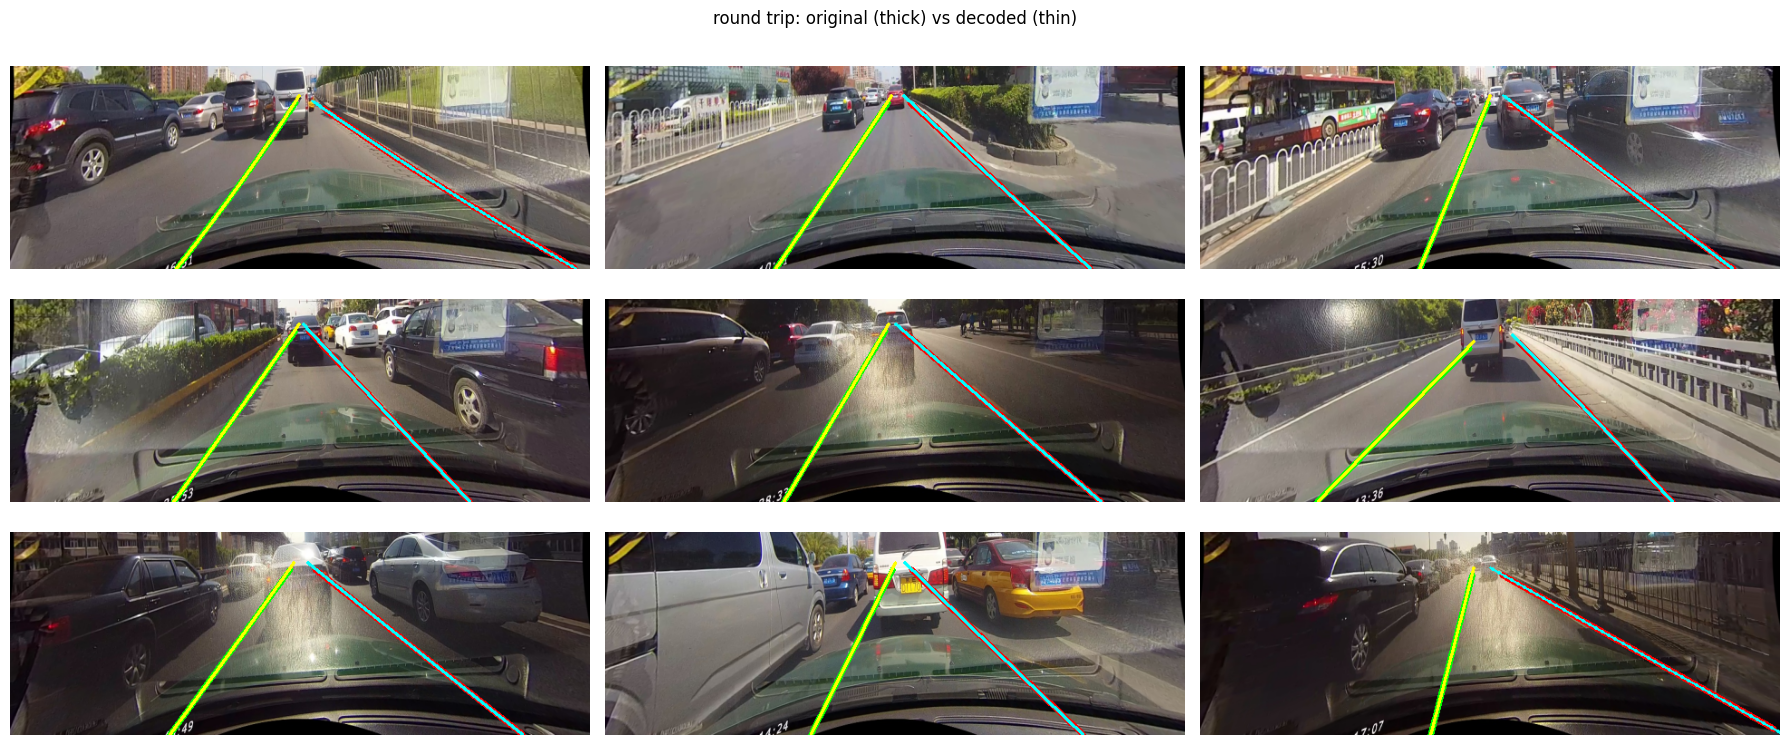

In [ ]:
images_val, lanes_val, meta_val = load('val')
check_idx = np.arange(500)
decoded = np.full((len(check_idx), 2, H), np.nan, np.float32)
mask_ious = []
for j in range(len(check_idx)):
	i = check_idx[j]
	for k in range(2):
		polygon = lane_to_polygon(lanes_val[i, k])
		if polygon is None:
			continue
		original = np.zeros((H, W), np.uint8)
		rows = np.where(np.isfinite(lanes_val[i, k]))[0]
		points = np.stack([lanes_val[i, k][rows], rows], 1).round().astype(np.int32)
		cv2.polylines(original, [points], False, 1, BAND)
		restored = np.zeros((H, W), np.uint8)
		cv2.fillPoly(restored, [polygon], 1)
		mask_ious.append(iou(original, restored))
		decoded[j, k], error = mask_to_lane(restored)
print('mask IoU after round trip: mean', round(np.mean(mask_ious), 4), '| min', round(np.min(mask_ious), 4))
display(evaluate(decoded, 'val', check_idx)[0].round(4))
show_pred(images_val, lanes_val, decoded[:9], check_idx[:9], 'round trip: original (thick) vs decoded (thin)', f"{FIGURES_DIR}/yolo_round_trip.png")

In [ ]:
def write_split(split_name, out_name, idx):
	images, lanes, meta = load(split_name)
	os.makedirs(f"{YOLO_DATA}/images/{out_name}", exist_ok=True)
	os.makedirs(f"{YOLO_DATA}/labels/{out_name}", exist_ok=True)

	def write_one(i):
		img = np.ascontiguousarray(images[i][:, :, ::-1])
		cv2.imwrite(f"{YOLO_DATA}/images/{out_name}/{i:06d}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 95])
		lines = []
		for k in range(2):
			polygon = lane_to_polygon(lanes[i, k])
			if polygon is not None:
				coords = (polygon / [W, H]).flatten()
				lines.append(str(k) + ' ' + ' '.join(f"{v:.5f}" for v in coords))
		with open(f"{YOLO_DATA}/labels/{out_name}/{i:06d}.txt", 'w') as f:
			f.write('\n'.join(lines))

	with ThreadPoolExecutor(16) as pool:
		list(tqdm(pool.map(write_one, idx), total=len(idx), desc=out_name))

val_idx = np.sort(np.random.default_rng(SEED).choice(9500, 2000, replace=False))
if not os.path.exists(f"{YOLO_DATA}/data.yaml"):
	write_split('train', 'train', np.arange(45000))
	write_split('val', 'val', val_idx)
	data = {'path': YOLO_DATA, 'train': 'images/train', 'val': 'images/val', 'names': {0: 'left', 1: 'right'}}
	yaml.safe_dump(data, open(f"{YOLO_DATA}/data.yaml", 'w'))
print(len(os.listdir(f"{YOLO_DATA}/images/train")), 'train images |', len(os.listdir(f"{YOLO_DATA}/images/val")), 'val images')

train:   0%|          | 0/45000 [00:00<?, ?it/s]

val:   0%|          | 0/2000 [00:00<?, ?it/s]

45000 train images | 2000 val images


In [6]:
def train_yolo(run, weights, epochs, freeze=None, fraction=1.0):
	model = YOLO(weights)
	model.train(data=f"{YOLO_DATA}/data.yaml", epochs=epochs, imgsz=640, batch=32, workers=8,
	            fliplr=0.0, mosaic=0.0, freeze=freeze, fraction=fraction,
	            seed=SEED, deterministic=True, project=YOLO_RUNS, name=run, exist_ok=True)
	os.makedirs(f"{MODELS_DIR}/{run}", exist_ok=True)
	shutil.copy(f"{YOLO_RUNS}/{run}/weights/best.pt", f"{MODELS_DIR}/{run}/best.pt")
	return f"{MODELS_DIR}/{run}/best.pt"

def predict_split(model, split, idx=None):
	images, _, meta = load(split)
	if idx is None:
		idx = np.arange(len(meta))
	lanes = np.full((len(idx), 2, H), np.nan, np.float32)
	conf = np.zeros((len(idx), 2), np.float32)
	sigma = np.full((len(idx), 2, H), np.nan, np.float32)
	for start in tqdm(range(0, len(idx), 64), leave=False):
		batch = []
		for i in idx[start:start + 64]:
			batch.append(np.ascontiguousarray(images[i][:, :, ::-1]))
		results = model.predict(batch, imgsz=[H, W], conf=0.05, verbose=False)
		for j in range(len(results)):
			lanes[start + j], conf[start + j], sigma[start + j] = decode_result(results[j])
	return lanes, conf, sigma

def apply_threshold(lanes, conf, threshold):
	out = lanes.copy()
	out[conf < threshold] = np.nan
	return out

In [8]:
RUN = 'yolo26n_seg'
best_path = f"{MODELS_DIR}/{RUN}/best.pt"
print(best_path, os.path.exists(best_path))
FUSION_DIR = f"{BASE_DIR}/fusion_inputs"
os.makedirs(FUSION_DIR, exist_ok=True)
model = YOLO(best_path)
for split in ['val', 'test_culane', 'test_bdd']:
	path = f"{FUSION_DIR}/yolo_{split}.npz"
	if os.path.exists(path):
		print(split, 'already saved')
		continue
	lanes, conf, sigma = predict_split(model, split)
	np.savez_compressed(path, lanes=lanes, conf=conf, sigma=sigma)
	print(split, 'saved', lanes.shape)

/content/drive/MyDrive/lane detection/models/yolo26n_seg/best.pt True


  0%|          | 0/149 [00:00<?, ?it/s]

val saved (9500, 2, 224)


  0%|          | 0/60 [00:00<?, ?it/s]

test_culane saved (3798, 2, 224)


  0%|          | 0/40 [00:00<?, ?it/s]

test_bdd saved (2560, 2, 224)


In [9]:
FUSION_DIR = f"{BASE_DIR}/fusion_inputs"
os.makedirs(FUSION_DIR, exist_ok=True)
model = YOLO(best_path)
for split in ['val', 'test_culane', 'test_bdd']:
	path = f"{FUSION_DIR}/yolo_{split}.npz"
	if os.path.exists(path):
		print(split, 'already saved')
		continue
	lanes, conf, sigma = predict_split(model, split)
	np.savez_compressed(path, lanes=lanes, conf=conf, sigma=sigma)
	print(split, 'saved', lanes.shape)

val already saved
test_culane already saved
test_bdd already saved


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=0.02, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo_quick_check, nbs=64, nms=None, opset=None, optimize

  0%|          | 0/1 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


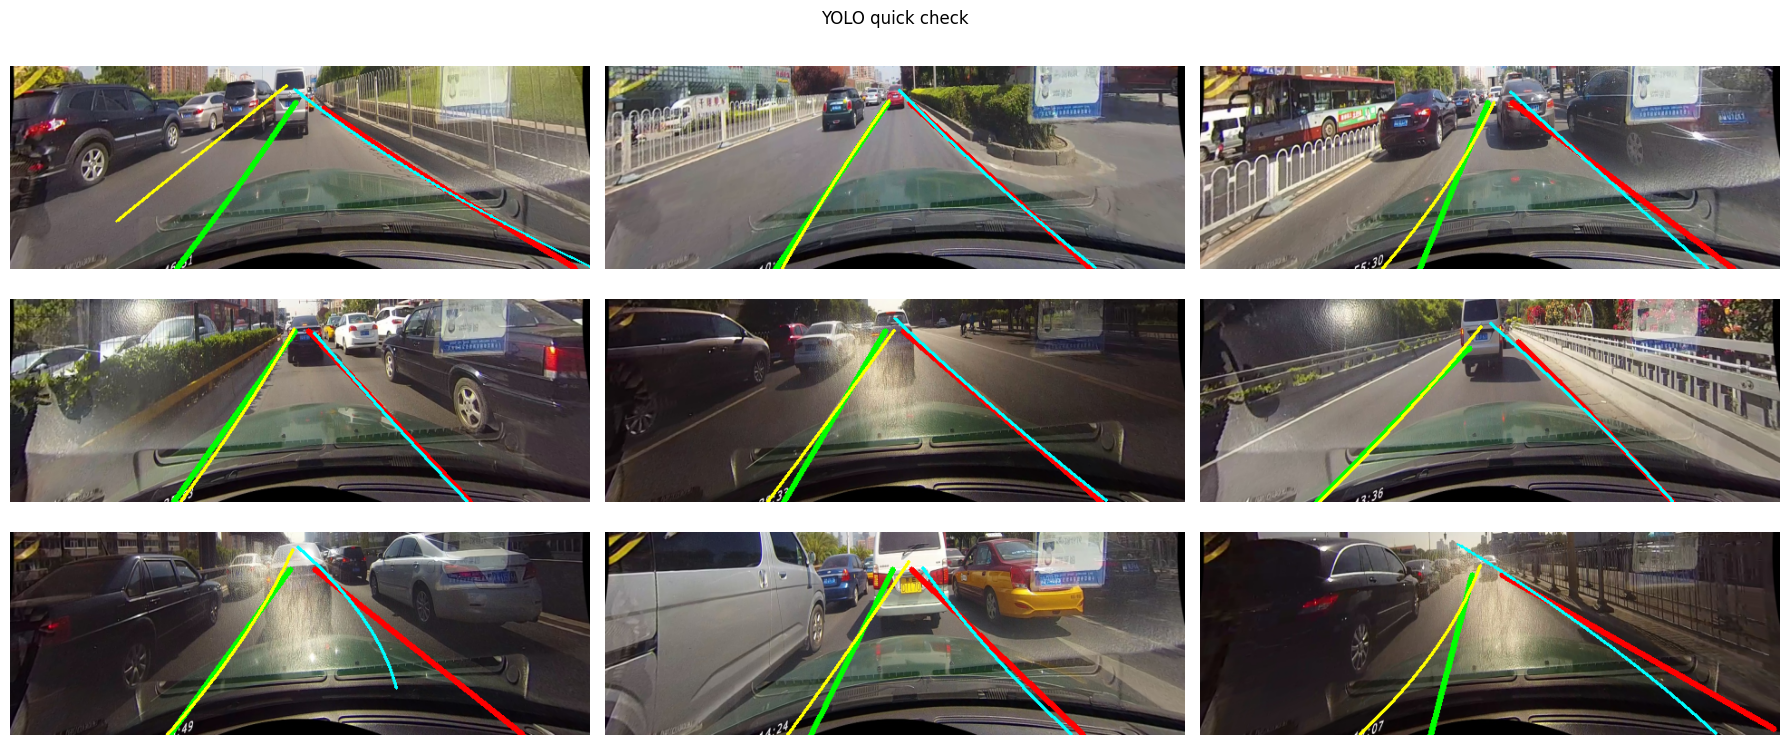

In [ ]:

quick_path = train_yolo('yolo_quick_check', 'yolo26n-seg.pt', epochs=3, fraction=0.02)
quick_model = YOLO(quick_path)
pred, conf, sigma = predict_split(quick_model, 'val', np.arange(9))
show_pred(images_val, lanes_val, apply_threshold(pred, conf, 0.1), np.arange(9), 'YOLO quick check')

In [ ]:
RUN = 'yolo26n_seg'
best_path = train_yolo(RUN, 'yolo26n-seg.pt', EPOCHS)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo26n_seg, nbs=64, nms=None, opset=None, optimize=Fals

In [ ]:
from ultralytics.utils.torch_utils import get_flops

def finish(run, model_path, mode):
	model = YOLO(model_path)
	lanes, conf, sigma = predict_split(model, 'val')
	best_threshold = 0.3
	best_f1 = -1
	table = None
	for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
		t = evaluate(apply_threshold(lanes, conf, threshold), 'val')[0]
		print(run, 'threshold', threshold, 'val F1', round(t.loc['all', 'f1'], 4))
		if t.loc['all', 'f1'] > best_f1:
			best_threshold = threshold
			best_f1 = t.loc['all', 'f1']
			table = t

	images, _, _ = load('val')
	frame = np.ascontiguousarray(images[0][:, :, ::-1])
	for _ in range(20):
		decode_result(model.predict(frame, imgsz=[H, W], verbose=False)[0])
	start = time.time()
	for _ in range(100):
		decode_result(model.predict(frame, imgsz=[H, W], verbose=False)[0])
	ms = (time.time() - start) * 10
	params = sum(p.numel() for p in model.model.parameters())
	gflops = get_flops(model.model, imgsz=640)

	onnx_path = model.export(format='onnx', imgsz=[H, W])
	shutil.copy(onnx_path, f"{MODELS_DIR}/{run}/model.onnx")

	config = {'model': 'yolo26n-seg', 'mode': mode, 'input': [W, H], 'band_px': BAND, 'threshold': best_threshold,
	          'epochs': EPOCHS, 'batch': 32, 'fliplr': 0.0, 'mosaic': 0.0, 'seed': SEED}
	yaml.safe_dump(config, open(f"{MODELS_DIR}/{run}/config.yaml", 'w'))

	metrics = table.loc['all'].to_dict()
	metrics['threshold'] = best_threshold
	metrics['ms_gpu_end_to_end'] = ms
	metrics['params'] = params
	metrics['gflops_640x640'] = gflops
	json.dump(metrics, open(f"{MODELS_DIR}/{run}/metrics.json", 'w'), indent=2, default=float)

	row = {'run': run, 'detector': 'yolo26n_seg', 'backbone': 'yolo26n', 'mode': mode, 'tracker': 'none', 'split': 'val',
	       'resolution': f"{W}x{H}", 'params': params, 'gflops': round(gflops, 2), 'ms_per_frame': round(ms, 2),
	       'device': 'gpu', 'hardware': torch.cuda.get_device_name(0), 'threshold': best_threshold}
	row.update(table.loc['all'].round(4).to_dict())
	log_result(row)

	for split in ['test_culane', 'test_bdd']:
		lanes, conf, sigma = predict_split(model, split)
		save_predictions(run, split, apply_threshold(lanes, conf, best_threshold), conf, sigma)
	display(table.round(4))
	print(run, 'val F1', round(best_f1, 4), '|', round(ms, 2), 'ms |', round(params / 1e6, 2), 'M params |', round(gflops, 2), 'GFLOPs')
	return best_threshold

threshold = finish(RUN, best_path, 'finetune')

  0%|          | 0/149 [00:00<?, ?it/s]

yolo26n_seg threshold 0.1 val F1 0.6965
yolo26n_seg threshold 0.2 val F1 0.7183
yolo26n_seg threshold 0.3 val F1 0.7294
yolo26n_seg threshold 0.4 val F1 0.7329
yolo26n_seg threshold 0.5 val F1 0.7293
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n-seg summary (fused): 137 layers, 2,704,026 parameters, 0 gradients, 3.2 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/lane detection/models/yolo26n_seg/best.pt' with input shape (1, 3, 224, 640) BCHW and output shape(s) ((1, 38, 2940), (1, 32, 56, 160)) (6.3 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 193ms
Prepared 3 packages in 274ms
Installed 3 packages in 7ms
 + colorama==0.4.6
 + onnxruntime==1.32.0
 + onnxsli

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

,n,precision,recall,f1,fp,f1_left,f1_right,f1@0.7
condition,,,,,,,,
all,9500,0.8454,0.6468,0.7329,2075,0.7565,0.7072,0.5528
unknown,9500,0.8454,0.6468,0.7329,2075,0.7565,0.7072,0.5528


yolo26n_seg val F1 0.7329 | 35.93 ms | 3.08 M params | 10.42 GFLOPs


In [ ]:
model = YOLO(best_path)
pred_val, conf_val, sigma_val = predict_split(model, 'val')
pred_val = apply_threshold(pred_val, conf_val, threshold)
table, records = evaluate(pred_val, 'val')
idx = np.random.default_rng(SEED).choice(len(pred_val), 9, replace=False)
show_pred(images_val, lanes_val, pred_val[idx], idx, 'YOLO26n-seg: random val frames', f"{FIGURES_DIR}/{RUN}_random.png")
frame_score = []
for r in records:
	if any(r['gt_on']):
		frame_score.append(np.nan_to_num(r['side']).mean())
	else:
		frame_score.append(9)
worst = np.argsort(frame_score)[:6]
show_pred(images_val, lanes_val, pred_val[worst], worst, 'YOLO26n-seg: worst val frames', f"{FIGURES_DIR}/{RUN}_worst.png")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
frozen_path = train_yolo('yolo26n_seg_frozen', 'yolo26n-seg.pt', EPOCHS, freeze=10)
finish('yolo26n_seg_frozen', frozen_path, 'frozen')

scratch_path = train_yolo('yolo26n_seg_scratch', 'yolo26n-seg.yaml', EPOCHS)
finish('yolo26n_seg_scratch', scratch_path, 'scratch')

In [ ]:
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()